In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

cwd = Path.cwd()

if (cwd / "component4").exists():
    ROOT = cwd
elif cwd.name == "notebooks" and cwd.parent.name == "component4":
    ROOT = cwd.parent.parent
else:
    ROOT = cwd

sys.path.insert(0, str(ROOT))

OUTPUT_DIR = ROOT / "component4" / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Project root:", ROOT)

Project root: e:\J26-DS-349


In [2]:
from component4.src.source_detection import (
    classify_uncertainty_source
)

print("Source detector imported successfully.")

Source detector imported successfully.


In [3]:
rng = np.random.default_rng(42)

scenarios = []

# -------------------------
# Stable
# Low UP + Low UE
# -------------------------
for i in range(12):
    scenarios.append({
        "scenario_id": f"S{i+1:02d}",
        "preference_instability": rng.uniform(0.05, 0.18),
        "evidence_instability": rng.uniform(0.05, 0.18),
        "expected_state": "Stable"
    })


# -------------------------
# Preference-sensitive
# High UP + Low UE
# -------------------------
for i in range(12):
    scenarios.append({
        "scenario_id": f"P{i+1:02d}",
        "preference_instability": rng.uniform(0.40, 0.70),
        "evidence_instability": rng.uniform(0.05, 0.18),
        "expected_state": "Preference-sensitive"
    })


# -------------------------
# Evidence-sensitive
# Low UP + High UE
# -------------------------
for i in range(12):
    scenarios.append({
        "scenario_id": f"E{i+1:02d}",
        "preference_instability": rng.uniform(0.05, 0.18),
        "evidence_instability": rng.uniform(0.40, 0.70),
        "expected_state": "Evidence-sensitive"
    })


# -------------------------
# Mixed
# Both sources have
# similar meaningful impact
# -------------------------
for i in range(12):

    base = rng.uniform(0.40, 0.65)

    difference = rng.uniform(
        -0.07,
        0.07
    )

    pref_value = np.clip(
        base + difference / 2,
        0,
        1
    )

    evidence_value = np.clip(
        base - difference / 2,
        0,
        1
    )

    scenarios.append({
        "scenario_id": f"M{i+1:02d}",
        "preference_instability": pref_value,
        "evidence_instability": evidence_value,
        "expected_state": "Mixed"
    })


controlled_cases = pd.DataFrame(scenarios)

print(
    "Controlled scenarios:",
    len(controlled_cases)
)

display(controlled_cases.head())

Controlled scenarios: 48


,scenario_id,preference_instability,evidence_instability,expected_state
0,S01,0.150614,0.107054,Stable
1,S02,0.161618,0.140658,Stable
2,S03,0.062243,0.176831,Stable
3,S04,0.148948,0.152188,Stable
4,S05,0.066655,0.108550,Stable


In [4]:
display(
    controlled_cases[
        "expected_state"
    ].value_counts()
)

expected_state
Stable                  12
Preference-sensitive    12
Evidence-sensitive      12
Mixed                   12
Name: count, dtype: int64

In [5]:
predicted_states = []
recommended_actions = []

for _, row in controlled_cases.iterrows():

    state, action = classify_uncertainty_source(
        row["preference_instability"],
        row["evidence_instability"]
    )

    predicted_states.append(state)
    recommended_actions.append(action)


controlled_cases["predicted_state"] = (
    predicted_states
)

controlled_cases["recommended_action"] = (
    recommended_actions
)

controlled_cases["correct"] = (
    controlled_cases["expected_state"]
    ==
    controlled_cases["predicted_state"]
)

display(controlled_cases.head(15))

,scenario_id,preference_instability,evidence_instability,expected_state,predicted_state,recommended_action,correct
0,S01,0.150614,0.107054,Stable,Stable,Recommend,True
1,S02,0.161618,0.140658,Stable,Stable,Recommend,True
2,S03,0.062243,0.176831,Stable,Stable,Recommend,True
3,S04,0.148948,0.152188,Stable,Stable,Recommend,True
4,S05,0.066655,0.108550,Stable,Stable,Recommend,True
5,S06,0.098204,0.170479,Stable,Stable,Recommend,True
6,S07,0.133702,0.156959,Stable,Stable,Recommend,True
7,S08,0.107644,0.079541,Stable,Stable,Recommend,True
8,S09,0.122096,0.058296,Stable,Stable,Recommend,True
9,S10,0.157592,0.132116,Stable,Stable,Recommend,True


In [6]:
y_true = controlled_cases["expected_state"]
y_pred = controlled_cases["predicted_state"]

accuracy = accuracy_score(
    y_true,
    y_pred
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

print(
    "Controlled Scenario Accuracy:",
    round(accuracy, 4)
)

print(
    "Controlled Scenario Macro-F1:",
    round(macro_f1, 4)
)

Controlled Scenario Accuracy: 1.0
Controlled Scenario Macro-F1: 1.0


In [7]:
print(
    classification_report(
        y_true,
        y_pred,
        digits=4,
        zero_division=0
    )
)

                      precision    recall  f1-score   support

  Evidence-sensitive     1.0000    1.0000    1.0000        12
               Mixed     1.0000    1.0000    1.0000        12
Preference-sensitive     1.0000    1.0000    1.0000        12
              Stable     1.0000    1.0000    1.0000        12

            accuracy                         1.0000        48
           macro avg     1.0000    1.0000    1.0000        48
        weighted avg     1.0000    1.0000    1.0000        48



In [8]:
labels = [
    "Stable",
    "Preference-sensitive",
    "Evidence-sensitive",
    "Mixed"
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

display(cm_df)

,Stable,Preference-sensitive,Evidence-sensitive,Mixed
Stable,12,0,0,0
Preference-sensitive,0,12,0,0
Evidence-sensitive,0,0,12,0
Mixed,0,0,0,12


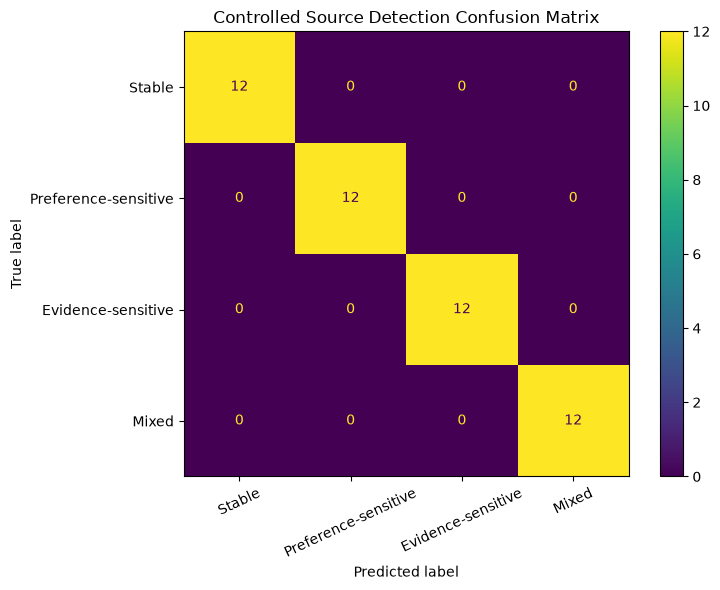

In [9]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_cm.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "Controlled Source Detection Confusion Matrix"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()

In [10]:
mock_state, mock_action = (
    classify_uncertainty_source(
        preference_instability=0.1749,
        evidence_instability=0.5190
    )
)

print(
    "Current mock scenario state:",
    mock_state
)

print(
    "Current mock scenario action:",
    mock_action
)

Current mock scenario state: Evidence-sensitive
Current mock scenario action: Warn


In [11]:
assert len(controlled_cases) == 48

assert set(
    controlled_cases["expected_state"]
) == set(labels)

assert controlled_cases[
    "predicted_state"
].notna().all()

assert 0 <= accuracy <= 1
assert 0 <= macro_f1 <= 1

print(
    "SOURCE DETECTION EVALUATION TESTS: PASSED"
)

SOURCE DETECTION EVALUATION TESTS: PASSED


In [12]:
controlled_cases.to_csv(
    OUTPUT_DIR /
    "source_detection_controlled_cases.csv",
    index=False
)

cm_df.to_csv(
    OUTPUT_DIR /
    "source_detection_confusion_matrix.csv"
)

metrics_df = pd.DataFrame({
    "metric": [
        "Accuracy",
        "Macro-F1"
    ],
    "value": [
        accuracy,
        macro_f1
    ]
})

metrics_df.to_csv(
    OUTPUT_DIR /
    "source_detection_metrics.csv",
    index=False
)

print(
    "WP10 evaluation outputs saved."
)

WP10 evaluation outputs saved.
